In [3]:
import pandas as pd
from pathlib import Path
raw = Path("../data/raw")
for n in ["CPI", "policy_rate", "PKRUSD", "Brent_oil"]:
    df=pd.read_csv(raw/ f"{n}.csv")
    print(f"\n==== {n} ====", df.shape)
    print(df.dtypes)
    print(df.head(3))
    print(df.tail(3))




==== CPI ==== (122, 8)
Dataset                           str
Series Key                        str
Series                            str
Observation Date                  str
Observation Value             float64
Unit                              str
Observation Status                str
Observation Status Comment    float64
dtype: object
                                  Dataset                Series Key  \
0  Inflation Snapshot (New Base: 2015-16)  TS_GP_PT_CPI_M.P00011516   
1  Inflation Snapshot (New Base: 2015-16)  TS_GP_PT_CPI_M.P00011516   
2  Inflation Snapshot (New Base: 2015-16)  TS_GP_PT_CPI_M.P00011516   

              Series Observation Date  Observation Value     Unit  \
0  CPI National -YoY      31-Aug-2026               11.1  Percent   
1  CPI National -YoY      31-Jul-2026                9.2  Percent   
2  CPI National -YoY      30-Jun-2026               11.1  Percent   

  Observation Status  Observation Status Comment  
0             Normal                         

In [2]:
%pip install pandas numpy matplotlib statsmodels scikit-Learn

   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
    --------------------------------------- 0.3/10.7 MB ? eta -:--:--
   --- ------------------------------------ 1.0/10.7 MB 3.3 MB/s eta 0:00:03
   ------ --------------------------------- 1.8/10.7 MB 3.8 MB/s eta 0:00:03
   -------- ------------------------------- 2.4/10.7 MB 3.8 MB/s eta 0:00:03
   ------------ --------------------------- 3.4/10.7 MB 3.8 MB/s eta 0:00:02
   -------------- ------------------------- 3.9/10.7 MB 3.4 MB/s eta 0:00:02
   ---------------- ----------------------- 4.5/10.7 MB 3.4 MB/s eta 0:00:02
   ------------------ --------------------- 5.0/10.7 MB 3.2 MB/s eta 0:00:02
   ------------------- -------------------- 5.2/10.7 MB 2.9 MB/s eta 0:00:02
   -------------------- ------------------- 5.5/10.7 MB 2.8 MB/s eta 0:00:02
   --------------------- ------------------ 5.8/10.7 MB 2.6 MB/s eta 0:00:02
   ---------------------- ----------------- 6.0/10.7 MB 2.5 MB/s eta 0:00:02
   ----------


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


        date  cpi_yoy    month
0 2016-07-31     3.17  2016-07
1 2016-08-31     2.80  2016-08
2 2016-09-30     3.23  2016-09
          date  cpi_yoy    month
119 2026-06-30     11.1  2026-06
120 2026-07-31      9.2  2026-07
121 2026-08-31     11.1  2026-08
missing: 0 I duplicate months : 0


<Axes: title={'center': 'CPI YoY (%)'}, xlabel='date'>

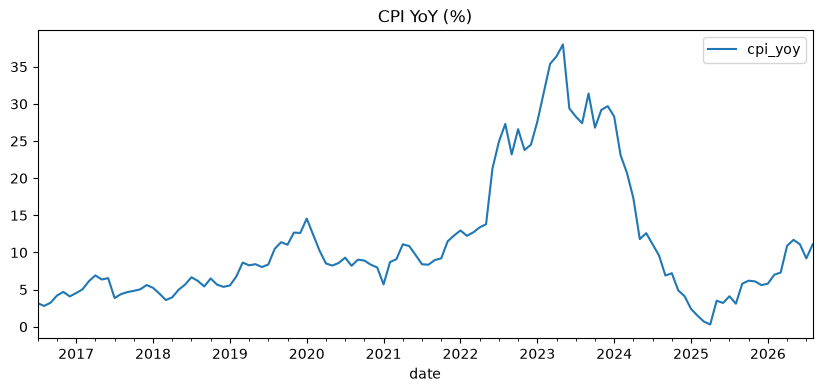

In [12]:
CPI = pd.read_csv(raw / "CPI.csv")
CPI["date"] = pd.to_datetime(CPI["Observation Date"], format="%d-%b-%Y")
CPI = (CPI.rename(columns={"Observation Value": "cpi_yoy"})
[["date", "cpi_yoy"]]
.sort_values("date")
.reset_index(drop=True))
CPI["month"] =CPI["date"].dt.to_period("M")
print(CPI.head(3)); print(CPI.tail(3))
print("missing:", CPI["cpi_yoy"].isna().sum(), "I duplicate months :", CPI["month"].duplicated().sum())
CPI.plot(x="date", y="cpi_yoy", figsize=(10, 4), title="CPI YoY (%)")






In [17]:
for n in ["policy_rate", "PKRUSD", "Brent_oil"]:
    df=pd.read_csv(raw / f"{n}.csv")
    df =df.loc[:, df.nunique() > 1]
    print (f"\n==== {n} ====", df.shape)
    print(df.head(2). to_string())
    print(df.tail(2). to_string())




==== policy_rate ==== (3, 57)
                                          ITEMS  17-AUG-2009  25-NOV-2009  02-AUG-2010  30-SEP-2010  30-NOV-2010  01-AUG-2011  10-OCT-2011  13-AUG-2012  08-OCT-2012  17-DEC-2012  11-FEB-2013  24-JUN-2013  16-SEP-2013  18-NOV-2013  17-NOV-2014  26-JAN-2015  24-MAR-2015  25-MAY-2015  14-SEP-2015  23-MAY-2016  29-JAN-2018  28-MAY-2018  16-JUL-2018  01-OCT-2018  03-DEC-2018  01-FEB-2019  01-APR-2019  21-MAY-2019  17-JUL-2019  18-MAR-2020  25-MAR-2020  16-APR-2020  17-APR-2020  16-MAY-2020  18-MAY-2020  26-JUN-2020  21-SEP-2021  22-NOV-2021  15-DEC-2021  08-APR-2022  24-MAY-2022  13-JUL-2022  28-NOV-2022  24-JAN-2023  03-MAR-2023  05-APR-2023  27-JUN-2023  11-JUN-2024  30-JUL-2024  13-SEP-2024  05-NOV-2024  17-DEC-2024  28-JAN-2025  06-MAY-2025  16-DEC-2025  28-APR-2026
0  . State Bank of Pakistan's Reverse Repo Rate         13.0         12.5         13.0         13.5         14.0         13.5         12.0         10.5         10.0          9.5          9.5   

In [22]:
import pandas as pd
import pathlib as path
raw =Path("../data/raw")
cpi=pd.read_csv(raw/ "CPI.csv")
cpi["month"] =pd.to_datetime(cpi["Observation Date"], format="%d-%b-%Y").dt.to_period("M")
cpi= cpi.rename(columns={"Observation Value": "cpi_yoy"}).sort_values("month")
fx=pd.read_csv(raw/ "PKRUSD.csv")
fx["month"] =pd.to_datetime(fx["Observation Date"], format="%d-%b-%Y").dt.to_period("M")
fx= fx.rename(columns={"Observation Value": "PKR_USD"})[["month","PKR_USD"]].sort_values("month")
oil=pd.read_csv(raw/ "Brent_oil.csv")
oil["month"] =pd.to_datetime(oil["observation_date"]).dt.to_period("M")
oil= oil.rename(columns={"POILBREUSDM": "brent_usd"})[["month","brent_usd"]].sort_values("month")
pr=pd.read_csv(raw/ "policy_rate.csv")
row= pr[pr["ITEMS"].str.contains("Target", na=False)].drop(columns="ITEMS").iloc[0]
pol = row.rename_axis("date").reset_index(name="policy_rate")
pol["date"] = pd.to_datetime(pol["date"].str.title(), format="%d-%b-%Y", errors="coerce")
pol["policy_rate"] = pd.to_numeric(pol["policy_rate"], errors="coerce")
pol = pol.dropna().sort_values("date").set_index("date")["policy_rate"]
pol = pol.groupby(pol.index.to_period("M")).last()
pol = pol.reindex(pd.period_range(pol.index.min(), cpi["month"].max(), freq="M")).ffill()
pol = pol.rename_axis("month").reset_index()

df = (cpi.merge(pol, on="month", how="left")
         .merge(fx, on="month", how="left")
         .merge(oil, on="month", how="left")
         .sort_values("month").reset_index(drop=True))

print(df.shape)
print(df.isna().sum())
print(df.head(3)); print(df.tail(3))
df.to_csv("../data/processed/monthly.csv", index=False)


(122, 12)
Dataset                         0
Series Key                      0
Series                          0
Observation Date                0
cpi_yoy                         0
Unit                            0
Observation Status              0
Observation Status Comment    121
month                           0
policy_rate                     0
PKR_USD                         0
brent_usd                       1
dtype: int64
                                  Dataset                Series Key  \
0  Inflation Snapshot (New Base: 2015-16)  TS_GP_PT_CPI_M.P00011516   
1  Inflation Snapshot (New Base: 2015-16)  TS_GP_PT_CPI_M.P00011516   
2  Inflation Snapshot (New Base: 2015-16)  TS_GP_PT_CPI_M.P00011516   

              Series Observation Date  cpi_yoy     Unit Observation Status  \
0  CPI National -YoY      31-Jul-2016     3.17  Percent             Normal   
1  CPI National -YoY      31-Aug-2016     2.80  Percent             Normal   
2  CPI National -YoY      30-Sep-2016     3.23  Pe

In [23]:
df = pd.read_csv("../data/processed/monthly.csv")
print(df[df["Observation Status Comment"].notna()].T)
df = df[["month", "cpi_yoy", "policy_rate", "PKR_USD", "brent_usd"]]
df = df.rename(columns={"PKR_USD": "pkr_usd"})
df.to_csv("../data/processed/monthly.csv", index=False)
print(df.shape)
print(df.tail(3))

                                                               117
Dataset                     Inflation Snapshot (New Base: 2015-16)
Series Key                                TS_GP_PT_CPI_M.P00011516
Series                                           CPI National -YoY
Observation Date                                       30-Apr-2026
cpi_yoy                                                       10.9
Unit                                                       Percent
Observation Status                                          Normal
Observation Status Comment                                     0.0
month                                                      2026-04
policy_rate                                                   11.5
PKR_USD                                                 279.175974
brent_usd                                               102.813636
(122, 5)
       month  cpi_yoy  policy_rate     pkr_usd  brent_usd
119  2026-06     11.1         11.5  278.579554  84.487727
120 

             cpi_yoy  policy_rate  pkr_usd  brent_usd
cpi_yoy         1.00         0.76     0.46       0.49
policy_rate     0.76         1.00     0.77       0.52
pkr_usd         0.46         0.77     1.00       0.50
brent_usd       0.49         0.52     0.50       1.00


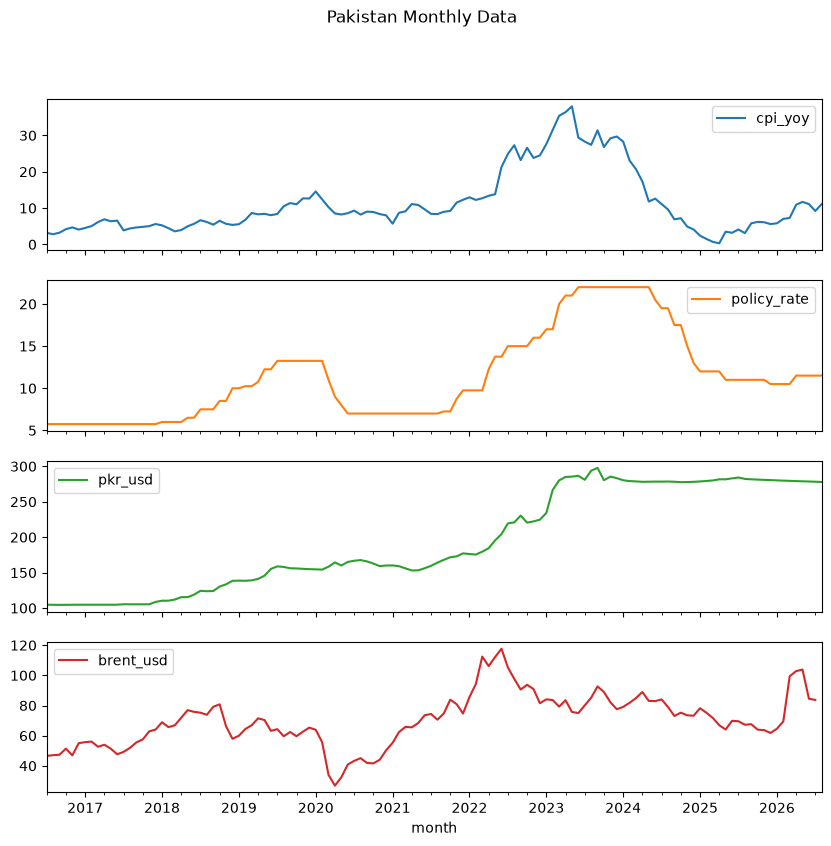

In [27]:
import pandas as pd
df=pd.read_csv("../data/processed/monthly.csv", parse_dates=["month"]).set_index("month")
df.plot(subplots=True, figsize=(10,9), title= "Pakistan Monthly Data")
print(df.corr().round(2))



In [28]:
import pandas as pd
df = pd.read_csv("../data/processed/monthly.csv", parse_dates=["month"]).set_index("month")
f = pd.DataFrame(index=df.index)
f["cpi_yoy"] = df["cpi_yoy"]
for k in (1, 2, 3):
    f[f"cpi_lag{k}"] = df["cpi_yoy"].shift(k)
f["policy_rate"] = df["policy_rate"]
f["policy_chg_3m"] = df["policy_rate"].diff(3)
f["fx_chg_1m"] = df["pkr_usd"].pct_change(1, fill_method=None) * 100
f["fx_chg_3m"] = df["pkr_usd"].pct_change(3, fill_method=None) * 100
oil_pkr = df["brent_usd"] * df["pkr_usd"]
f["oil_pkr_chg_1m"] = oil_pkr.pct_change(1, fill_method=None) * 100
f["oil_pkr_chg_3m"] = oil_pkr.pct_change(3, fill_method=None) * 100
f["target"] = df["cpi_yoy"].shift(-1)

f.to_csv("../data/processed/features.csv")
d = f.dropna()
print("usable rows:", d.shape[0], "| from", d.index[0].strftime("%b %Y"), "to", d.index[-1].strftime("%b %Y"))
test = d.iloc[-24:]
print("Baseline MAE, last 24 months:", round((test["target"] - test["cpi_yoy"]).abs().mean(), 2))
print(f.tail(2).T.round(2))

usable rows: 118 | from Oct 2016 to Jul 2026
Baseline MAE, last 24 months: 1.23
month           2026-07-01  2026-08-01
cpi_yoy               9.20       11.10
cpi_lag1             11.10        9.20
cpi_lag2             11.70       11.10
cpi_lag3             10.90       11.70
policy_rate          11.50       11.50
policy_chg_3m         0.00        0.00
fx_chg_1m            -0.12       -0.11
fx_chg_3m            -0.34       -0.33
oil_pkr_chg_1m       -1.01         NaN
oil_pkr_chg_3m      -18.83         NaN
target               11.10         NaN


In [29]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
f = pd.read_csv("../data/processed/features.csv", parse_dates=["month"]).set_index("month")
d = f.dropna()
ar_cols = ["cpi_yoy", "cpi_lag1", "cpi_lag2", "cpi_lag3"]
all_cols = [c for c in d.columns if c != "target"]
models = { "AR (inflation lags only)": (LinearRegression(), ar_cols), "Ridge (all features)": (make_pipeline(StandardScaler(), Ridge(alpha=10)), all_cols), "Random forest (all features)": (RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0), all_cols),}
n_test = 24
actual = d["target"].iloc[-n_test:]
preds = {"Baseline (same as today)": d["cpi_yoy"].iloc[-n_test:]}
for name, (model, cols) in models.items():
    out = []
    for i in range(len(d) - n_test, len(d)):
        model.fit(d[cols].iloc[:i], d["target"].iloc[:i])
        out.append(model.predict(d[cols].iloc[[i]])[0])
    preds[name] = pd.Series(out, index=actual.index)

res = pd.DataFrame({n: {"MAE": (p - actual).abs().mean(),
                        "RMSE": np.sqrt(((p - actual) ** 2).mean())} for n, p in preds.items()}).T.round(2)
print(res.sort_values("MAE"))

                               MAE  RMSE
Ridge (all features)          1.09  1.32
Baseline (same as today)      1.23  1.59
AR (inflation lags only)      1.23  1.51
Random forest (all features)  1.49  1.87


In [31]:
import pandas as pd
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
d = pd.read_csv("../data/processed/features.csv", parse_dates=["month"]).set_index("month").dropna()
ar = ["cpi_yoy", "cpi_lag1", "cpi_lag2", "cpi_lag3"]
sets = {"AR only": ar,"+ policy rate": ar + ["policy_rate", "policy_chg_3m"],"+ PKR/USD": ar + ["fx_chg_1m", "fx_chg_3m"],"+ oil (PKR)": ar + ["oil_pkr_chg_1m", "oil_pkr_chg_3m"],
         "All features": [c for c in d.columns if c != "target"],}
def walk(cols, n_test):
    model = make_pipeline(StandardScaler(), Ridge(alpha=10))
    errs = []
    for i in range(len(d) - n_test, len(d)):
        model.fit(d[cols].iloc[:i], d["target"].iloc[:i])
        errs.append(abs(model.predict(d[cols].iloc[[i]])[0] - d["target"].iloc[i]))
    return np.mean(errs)
windows = (12, 24, 36)
rows = {"Baseline (same as today)": {n: (d["target"] - d["cpi_yoy"]).abs().iloc[-n:].mean() for n in windows}}
for name, cols in sets.items():
    rows[name] = {n: walk(cols, n) for n in windows}
print(pd.DataFrame(rows).T.rename(columns=lambda n: f"last {n} mo").round(2))

                          last 12 mo  last 24 mo  last 36 mo
Baseline (same as today)        1.18        1.23        1.74
AR only                         1.17        1.55        2.13
+ policy rate                   1.17        1.10        1.81
+ PKR/USD                       1.52        1.66        2.18
+ oil (PKR)                     0.88        1.34        1.99
All features                    1.15        1.09        1.87


In [33]:
import pandas as pd
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
f = pd.read_csv("../data/processed/features.csv", parse_dates=["month"]).set_index("month")
feat = [c for c in f.columns if c != "target"]

ar = ["cpi_yoy", "cpi_lag1", "cpi_lag2", "cpi_lag3"]
sets = {
    "AR only": ar,
    "+ policy rate": ar + ["policy_rate", "policy_chg_3m"],
    "+ PKR/USD": ar + ["fx_chg_1m", "fx_chg_3m"],
    "+ oil (PKR)": ar + ["oil_pkr_chg_1m", "oil_pkr_chg_3m"],
    "All features": feat,
}

def walk(d, cols, n_test, h):
    model = make_pipeline(StandardScaler(), Ridge(alpha=10))
    errs = []
    for i in range(len(d) - n_test, len(d)):
        tr = d.iloc[: i - h + 1]
        model.fit(tr[cols], tr["target"])
        errs.append(abs(model.predict(d[cols].iloc[[i]])[0] - d["target"].iloc[i]))
    return np.mean(errs)

base = "Baseline (same as today)"
for n in (24, 36):
    rows = {base: {}}
    for name in sets:
        rows[name] = {}
    for h in (1, 3, 6):
        d = f[feat].copy()
        d["target"] = f["cpi_yoy"].shift(-h)
        d = d.dropna()
        rows[base][f"h={h}"] = (d["target"] - d["cpi_yoy"]).abs().iloc[-n:].mean()
        for name, cols in sets.items():
            rows[name][f"h={h}"] = walk(d, cols, n, h)
    print(f"\nMAE, last {n} test months")
    print(pd.DataFrame(rows).T.round(2))



MAE, last 24 test months
                           h=1   h=3   h=6
Baseline (same as today)  1.23  2.76  5.05
AR only                   1.55  2.81  5.16
+ policy rate             1.10  2.10  5.38
+ PKR/USD                 1.66  2.86  5.24
+ oil (PKR)               1.34  2.82  5.24
All features              1.09  2.24  5.46

MAE, last 36 test months
                           h=1   h=3   h=6
Baseline (same as today)  1.74  3.58  6.49
AR only                   2.13  4.57  9.12
+ policy rate             1.81  4.22  9.48
+ PKR/USD                 2.18  4.44  9.01
+ oil (PKR)               1.99  4.67  9.38
All features              1.87  4.43  9.66


In [34]:
import pandas as pd, numpy as np
from pathlib import Path
raw = Path("../data/raw")
m = pd.read_csv(raw / "CPI_MoM.csv")
m["month"] = pd.to_datetime(m["Observation Date"], format="%d-%b-%Y").dt.to_period("M")
mom = pd.to_numeric(m["Observation Value"], errors="coerce")
mom.index = m["month"]
mom = mom.sort_index()
d = pd.read_csv("../data/processed/monthly.csv")
yoy = d.set_index(pd.to_datetime(d["month"]).dt.to_period("M"))["cpi_yoy"]
b = pd.DataFrame({"yoy": yoy, "mom": mom}).dropna()
b["actual"] = b["yoy"].shift(-1)
b["old"] = b["mom"].shift(11)
b["new_true"] = b["mom"].shift(-1)
def next_yoy(m_new):
    return ((1 + b["yoy"] / 100) * (1 + m_new / 100) / (1 + b["old"] / 100) - 1) * 100
cands = {
    "Baseline (same as today)": b["yoy"],
    "Base effect + avg MoM (3 mo)": next_yoy(b["mom"].rolling(3).mean()),
    "Base effect + avg MoM (6 mo)": next_yoy(b["mom"].rolling(6).mean()),
    "Base effect + avg MoM (12 mo)": next_yoy(b["mom"].rolling(12).mean()),
    "Ceiling: knows next MoM": next_yoy(b["new_true"]),
}
rows = {}
for name, p in cands.items():
    err = (p - b["actual"]).abs().dropna()
    rows[name] = {f"last {n} mo": err.iloc[-n:].mean() for n in (12, 24, 36)}
print(pd.DataFrame(rows).T.round(2))

                               last 12 mo  last 24 mo  last 36 mo
Baseline (same as today)             1.18        1.23        1.74
Base effect + avg MoM (3 mo)         0.95        0.96        1.18
Base effect + avg MoM (6 mo)         0.89        0.93        1.07
Base effect + avg MoM (12 mo)        0.80        0.80        1.02
Ceiling: knows next MoM              0.04        0.04        0.05


In [35]:
import pandas as pd, numpy as np
from pathlib import Path
raw = Path("../data/raw")
def load(name, col):
    x = pd.read_csv(raw / name)
    x["month"] = pd.to_datetime(x["Observation Date"], format="%d-%b-%Y").dt.to_period("M")
    s = pd.to_numeric(x["Observation Value"], errors="coerce")
    s.index = x["month"]
    return s.sort_index().rename(col)
yoy = load("CPI.csv", "yoy")
mom = load("CPI_MoM.csv", "mom")
last = yoy.index[-1]
nxt = last + 1
old = mom[nxt - 12]
new = mom.loc[:last].iloc[-12:].mean()
fc = ((1 + yoy[last] / 100) * (1 + new / 100) / (1 + old / 100) - 1) * 100
print(f"Latest actual: {last} = {yoy[last]:.1f}%")
print(f"Month dropping out ({nxt - 12}): MoM {old:.1f}%")
print(f"Assumed new-month MoM: {new:.2f}% (12-month average)")
print(f"Forecast for {nxt}: {fc:.1f}%   (typical miss about 0.8 points)")

Latest actual: 2026-08 = 11.1%
Month dropping out (2025-09): MoM 2.1%
Assumed new-month MoM: 0.90% (12-month average)
Forecast for 2026-09: 9.8%   (typical miss about 0.8 points)


In [36]:
import pandas as pd, numpy as np
from pathlib import Path
raw = Path("../data/raw")

def load(name, col):
    x = pd.read_csv(raw / name)
    x["month"] = pd.to_datetime(x["Observation Date"], format="%d-%b-%Y").dt.to_period("M")
    s = pd.to_numeric(x["Observation Value"], errors="coerce")
    s.index = x["month"]
    return s.sort_index().rename(col)

yoy = load("CPI.csv", "yoy")
mom = load("CPI_MoM.csv", "mom")

while mom.index[-1] > yoy.index[-1]:
    n = yoy.index[-1] + 1
    yoy.loc[n] = ((1 + yoy.iloc[-1] / 100) * (1 + mom[n] / 100) / (1 + mom[n - 12] / 100) - 1) * 100
    print(f"{n}: YoY not in file, derived from MoM = {yoy.loc[n]:.1f}%")

last = yoy.index[-1]
nxt = last + 1
old = mom[nxt - 12]
new = mom.loc[:last].iloc[-12:].mean()
fc = ((1 + yoy[last] / 100) * (1 + new / 100) / (1 + old / 100) - 1) * 100

print(f"Latest actual: {last} = {yoy[last]:.1f}%")
print(f"Month dropping out ({nxt - 12}): MoM {old:.1f}%")
print(f"Assumed new-month MoM: {new:.2f}% (12-month average)")
print(f"Forecast for {nxt}: {fc:.1f}%   (typical miss about 0.8 points)")

2026-09: YoY not in file, derived from MoM = 10.2%
Latest actual: 2026-09 = 10.2%
Month dropping out (2025-10): MoM 1.7%
Assumed new-month MoM: 0.83% (12-month average)
Forecast for 2026-10: 9.3%   (typical miss about 0.8 points)
